# Proyek UAS: Web Crawling dan Analisis PageRank (Web Structure Mining)
**Mata Kuliah:** Pencarian dan Penambangan Web (PPW)  
**Nama Mahasiswa:** Angger Nur Kuncoro  
**NIM:** 230411100155  
**Program Studi:** Teknik Informatika, Universitas Trunojoyo Madura  

---
Pada proyek ini, kita akan melakukan penambangan struktur web (*Web Structure Mining*) secara *end-to-end*. 
Tahapan proyek ini mencakup:
1. **Web Crawling Rekursif:** Mengunjungi halaman website dan mengekstraksi seluruh hyperlink internal maupun eksternal.
2. **Pemodelan Graf Web:** Membangun topologi graf berarah (*Directed Graph*) di mana simpul (*node*) adalah halaman web dan sisi (*edge*) adalah tautan antarhalaman.
3. **Kalkulasi Algoritma PageRank:** Mengimplementasikan algoritma PageRank secara matematis dari dasar (*from scratch*) dengan metode *Power Iteration* dan penanganan *dead-ends (dangling nodes)*.
4. **Validasi & Komparasi:** Membandingkan akurasi hasil perhitungan mandiri dengan pustaka standar industri `NetworkX`.
5. **Visualisasi Graf:** Memvisualisasikan jaringan keterhubungan website baik secara statis maupun interaktif.
6. **Analisis Otoritas Website:** Menentukan halaman/website mana yang memiliki otoritas dan tingkat kepentingan paling tinggi berdasarkan metrik PageRank.

## 1. Landasan Teori: Web Structure Mining & Algoritma PageRank

### 1.1 Web Structure Mining
*Web Structure Mining* adalah salah satu dari tiga pilar utama *Web Mining* (bersama *Web Content Mining* dan *Web Usage Mining*). Fokus utama dari bidang ini adalah menganalisis topologi tautan (*hyperlink*) antarhalaman di World Wide Web. Dengan memodelkan web sebagai sebuah graf berarah $G = (V, E)$:
- **Simpul ($V$):** Merepresentasikan halaman web atau dokumen HTML unik.
- **Sisi Berarah ($E$):** Merepresentasikan tautan hyperlink dari halaman sumber ke halaman tujuan ($u 
ightarrow v$).

### 1.2 Konsep Algoritma PageRank
Algoritma PageRank dikembangkan oleh Larry Page dan Sergey Brin (pendiri Google) pada tahun 1998 untuk mengukur tingkat kepentingan relatif dari sebuah halaman web berdasarkan struktur tautannya. 

Filosofi dasar PageRank:
> *"Sebuah halaman dianggap penting jika halaman tersebut banyak dirujuk (diberi link) oleh halaman lain, terutama jika halaman yang merujuknya juga merupakan halaman yang penting."*

### 1.3 Model Peselancar Acak (Random Surfer Model) & Persamaan Matematis
PageRank memodelkan perilaku seorang peselancar web yang mengklik tautan secara acak. Formula matematis PageRank dinyatakan sebagai berikut:

$$PR(u) = 
rac{1 - d}{N} + d \sum_{v \in B_u} 
rac{PR(v)}{L(v)}$$

**Keterangan Simbol:**
- $PR(u)$: Nilai PageRank dari halaman target $u$.
- $d$: *Damping Factor* (biasanya ditetapkan sebesar **0.85**), yaitu probabilitas peselancar terus mengikuti tautan keluar dari halaman saat ini.
- $1 - d$: Probabilitas peselancar merasa bosan dan melakukan *random jump* (teleportasi acak) ke sembarang halaman di web.
- $N$: Jumlah total halaman dalam graf.
- $B_u$: Himpunan semua halaman $v$ yang memiliki tautan masuk (*backlinks / in-degree*) ke halaman $u$.
- $L(v)$: Jumlah tautan keluar (*out-degree*) dari halaman $v$.

### 1.4 Penanganan Masalah Khusus
1. **Dead-Ends (Dangling Nodes):** Halaman yang tidak memiliki tautan keluar sama sekali ($L(v) = 0$). Jika tidak ditangani, nilai PageRank akan terserap dan lenyap (*rank sink*). Solusinya: bobot probabilitas dari *dangling nodes* didistribusikan merata ke seluruh $N$ halaman dalam graf.
2. **Spider Traps:** Sekelompok halaman yang hanya saling menautkan satu sama lain tanpa link keluar, sehingga memerangkap peselancar acak. Hal ini diatasi secara elegan oleh komponen *teleportation* $
rac{1 - d}{N}$.

## 2. Persiapan Lingkungan & Pustaka (Library)

Kita mengimpor pustaka yang diperlukan:
- `requests` & `BeautifulSoup`: Untuk mengambil halaman web dan mem-parsing elemen dokumen HTML.
- `urllib.parse`: Untuk normalisasi dan resolusi tautan absolut.
- `networkx`: Untuk analisis topologi graf dan pembanding algoritma PageRank.
- `pandas` & `numpy`: Untuk manipulasi data matriks dan tabel peringkat.
- `matplotlib.pyplot`: Untuk visualisasi graf statis dan kurva konvergensi.

In [1]:
import time
import re
from urllib.parse import urlparse, urljoin, urldefrag
from collections import deque
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

print("Semua pustaka berhasil dimuat dengan sukses!")

Semua pustaka berhasil dimuat dengan sukses!


## 3. Implementasi Web Crawler Rekursif (Breadth-First Search)

Pada tahap ini, kita merancang modul web crawling yang memiliki fitur:
1. **Normalisasi URL (`normalize_url`):** Membersihkan fragment URL (`#section`), parameter pelacak iklan (`utm_*`, `ref`), dan menghapus *trailing slash* ganda.
2. **Penyaringan Ekstensi File:** Mengabaikan berkas non-HTML seperti berkas gambar (`.jpg`, `.png`), dokumen dokumen (`.pdf`, `.docx`), atau arsip (`.zip`).
3. **Penelusuran Rekursif berbasis Antrean (BFS):** Membatasi kedalaman penelusuran (*Depth Limit*) dan batas maksimal halaman (*Max Pages*) agar penelusuran terkendali dan sopan terhadap server (*politeness delay*).

In [2]:
IGNORED_EXTENSIONS = (
    '.pdf', '.png', '.jpg', '.jpeg', '.gif', '.svg', '.webp', '.ico',
    '.zip', '.tar', '.gz', '.rar', '.7z', '.exe', '.dmg', '.apk',
    '.mp4', '.mp3', '.avi', '.mov', '.wmv', '.flv', '.wav',
    '.css', '.js', '.json', '.xml', '.csv', '.doc', '.docx', '.xls', '.xlsx'
)

def normalize_url(url: str) -> str:
    """Membersihkan dan menstandarisasi format URL."""
    try:
        url, _ = urldefrag(url.strip())
        parsed = urlparse(url)
        scheme = parsed.scheme.lower()
        if scheme not in ('http', 'https'):
            return ""
        netloc = parsed.netloc.lower()
        if netloc.endswith(':80') and scheme == 'http':
            netloc = netloc[:-3]
        elif netloc.endswith(':443') and scheme == 'https':
            netloc = netloc[:-4]
            
        path = parsed.path
        if not path:
            path = "/"
        elif len(path) > 1 and path.endswith('/'):
            path = path[:-1]
            
        # Bersihkan parameter tracking (utm_*, ref, dsb)
        filtered_query = []
        if parsed.query:
            for pair in parsed.query.split('&'):
                if '=' in pair:
                    k, v = pair.split('=', 1)
                    if not k.lower().startswith(('utm_', 'ref', 'fbclid', 'gclid')):
                        filtered_query.append(f"{k}={v}")
        query_str = f"?{'&'.join(filtered_query)}" if filtered_query else ""
        return f"{scheme}://{netloc}{path}{query_str}"
    except Exception:
        return ""

def is_valid_http_url(url: str) -> bool:
    if not url:
        return False
    try:
        parsed = urlparse(url)
        if parsed.scheme not in ('http', 'https') or not parsed.netloc:
            return False
        path_lower = parsed.path.lower()
        return not any(path_lower.endswith(ext) for ext in IGNORED_EXTENSIONS)
    except Exception:
        return False

def get_domain(url: str) -> str:
    try:
        return urlparse(url).netloc.lower()
    except Exception:
        return ""

Berikut adalah kelas `WebCrawler` yang mengekstrak relasi tautan antarhalaman:

In [3]:
class WebCrawler:
    def __init__(self, seed_url: str, max_depth: int = 2, max_pages: int = 30, delay: float = 0.2):
        self.seed_url = normalize_url(seed_url)
        self.seed_domain = get_domain(self.seed_url)
        self.max_depth = max_depth
        self.max_pages = max_pages
        self.delay = delay
        
        self.visited_urls = set()
        self.nodes = {}   # url -> {'title': str, 'domain': str, 'depth': int}
        self.edges = []   # list of (source_url, target_url, anchor_text)
        
    def crawl(self):
        queue = deque([(self.seed_url, 0)])
        self.visited_urls.add(self.seed_url)
        
        session = requests.Session()
        session.headers.update({
            "User-Agent": "Mozilla/5.0 (compatible; UASCrawler/1.0; +http://trunojoyo.ac.id)"
        })
        
        print(f"[*] Memulai crawling dari Seed URL: {self.seed_url}")
        print(f"[*] Batasan: Max Depth = {self.max_depth}, Max Pages = {self.max_pages}")
        
        while queue and len(self.visited_urls) <= self.max_pages:
            current_url, depth = queue.popleft()
            
            try:
                response = session.get(current_url, timeout=6, allow_redirects=True)
                final_url = normalize_url(response.url) or current_url
                
                content_type = response.headers.get("Content-Type", "").lower()
                if "text/html" not in content_type:
                    continue
                    
                soup = BeautifulSoup(response.text, "html.parser")
                page_title = soup.title.string.strip() if soup.title and soup.title.string else get_domain(final_url)
                page_title = re.sub(r'\s+', ' ', page_title).strip()
                
                self.nodes[final_url] = {
                    "title": page_title[:80],
                    "domain": get_domain(final_url),
                    "depth": depth
                }
                
                if depth >= self.max_depth:
                    continue
                    
                for a_tag in soup.find_all("a", href=True):
                    raw_href = a_tag["href"].strip()
                    if not raw_href or raw_href.startswith(("#", "javascript:", "mailto:", "tel:")):
                        continue
                        
                    abs_url = normalize_url(urljoin(final_url, raw_href))
                    if not is_valid_http_url(abs_url):
                        continue
                        
                    anchor_text = a_tag.get_text(strip=True)[:40] or "Link"
                    
                    if abs_url != final_url:
                        edge = (final_url, abs_url, anchor_text)
                        if edge not in self.edges:
                            self.edges.append(edge)
                            
                    # Batasi pencarian hanya dalam domain yang sama untuk analisis internal website
                    target_domain = get_domain(abs_url)
                    if target_domain == self.seed_domain or target_domain.endswith("." + self.seed_domain):
                        if abs_url not in self.visited_urls and len(self.visited_urls) < self.max_pages:
                            self.visited_urls.add(abs_url)
                            queue.append((abs_url, depth + 1))
                            
                if self.delay > 0:
                    time.sleep(self.delay)
                    
            except Exception as e:
                # Catat kesalahan akses tanpa menghentikan program
                pass
                
        # Pastikan seluruh target node terdaftar dalam nodes
        for src, dst, _ in self.edges:
            if src not in self.nodes:
                self.nodes[src] = {"title": src, "domain": get_domain(src), "depth": 0}
            if dst not in self.nodes:
                self.nodes[dst] = {"title": dst, "domain": get_domain(dst), "depth": self.max_depth + 1}
                
        print(f"[+] Selesai! Berhasil mengekstrak {len(self.nodes)} node halaman dan {len(self.edges)} relasi edge.")
        return self.nodes, self.edges

## 4. Eksekusi Crawling pada Website Target

Kita mengeksekusi *crawler* pada website target (contoh: Website Universitas Trunojoyo Madura `https://www.trunojoyo.ac.id` atau portal berita).
Hasil crawling akan disimpan ke dalam file CSV (`nodes_pagerank.csv` dan `edges_pagerank.csv`).

In [4]:
# Tentukan Seed URL website target
SEED_URL = "https://www.trunojoyo.ac.id"

# Inisialisasi dan jalankan crawler
crawler = WebCrawler(seed_url=SEED_URL, max_depth=2, max_pages=35, delay=0.1)
nodes_dict, edges_list = crawler.crawl()

# Simpan ke DataFrame
df_nodes = pd.DataFrame([
    {"url": u, "title": info["title"], "domain": info["domain"], "depth": info["depth"]}
    for u, info in nodes_dict.items()
])

df_edges = pd.DataFrame(edges_list, columns=["source", "target", "anchor_text"])

# Ekspor ke CSV untuk dokumentasi
df_nodes.to_csv("nodes_pagerank.csv", index=False)
df_edges.to_csv("edges_pagerank.csv", index=False)

print(f"Data simpul (nodes) tersimpan: {len(df_nodes)} baris")
print(f"Data keterhubungan (edges) tersimpan: {len(df_edges)} baris")
df_nodes.head(5)

[*] Memulai crawling dari Seed URL: https://www.trunojoyo.ac.id/
[*] Batasan: Max Depth = 2, Max Pages = 35


[+] Selesai! Berhasil mengekstrak 72 node halaman dan 72 relasi edge.
Data simpul (nodes) tersimpan: 72 baris
Data keterhubungan (edges) tersimpan: 72 baris


,url,title,domain,depth
0,https://www2.trunojoyo.ac.id/,"UTM Official – Unggul, Tangguh, Mandiri",www2.trunojoyo.ac.id,0
1,https://www2.trunojoyo.ac.id/sejarahutm,https://www2.trunojoyo.ac.id/sejarahutm,www2.trunojoyo.ac.id,3
2,https://www2.trunojoyo.ac.id/index.php/profil-...,https://www2.trunojoyo.ac.id/index.php/profil-...,www2.trunojoyo.ac.id,3
3,https://www2.trunojoyo.ac.id/visimisi,https://www2.trunojoyo.ac.id/visimisi,www2.trunojoyo.ac.id,3
4,https://www2.trunojoyo.ac.id/lhm,https://www2.trunojoyo.ac.id/lhm,www2.trunojoyo.ac.id,3


## 5. Pemodelan Topologi Graf Terarah (*Directed Graph*)

Dari data simpul dan sisi yang berhasil dikumpulkan, kita membentuk objek Graf Berarah (*DiGraph*) menggunakan pustaka `networkx`. 
Kita dapat menghitung metrik topologi seperti:
- **In-Degree ($d_{in}$):** Jumlah hyperlink yang mengarah masuk ke halaman (menunjukkan popularitas / *backlink*).
- **Out-Degree ($d_{out}$):** Jumlah hyperlink yang keluar dari halaman menuju halaman lain.
- **Kepadatan Graf (*Graph Density*):** Rasio jumlah tautan aktual terhadap jumlah maksimum tautan yang mungkin terbentuk.

In [5]:
G = nx.DiGraph()

# Tambahkan simpul dan sisi ke dalam graf
for _, row in df_nodes.iterrows():
    G.add_node(row["url"], title=row["title"], domain=row["domain"])

for _, row in df_edges.iterrows():
    if row["source"] in G and row["target"] in G:
        G.add_edge(row["source"], row["target"])

total_nodes = G.number_of_nodes()
total_edges = G.number_of_edges()
density = nx.density(G)

print("=== STATISTIK TOPOLOGI GRAF ===")
print(f"Total Simpul / Halaman (V) : {total_nodes}")
print(f"Total Tautan / Hyperlink (E): {total_edges}")
print(f"Kepadatan Graf (Density)    : {density:.6f}")

=== STATISTIK TOPOLOGI GRAF ===
Total Simpul / Halaman (V) : 72
Total Tautan / Hyperlink (E): 71
Kepadatan Graf (Density)    : 0.013889


## 6. Implementasi Algoritma PageRank *From Scratch* (Power Iteration)

Pada tahap ini, kita mengimplementasikan algoritma PageRank secara mandiri dari rumus dasarnya menggunakan metode **Power Iteration**.

**Langkah-langkah algoritma:**
1. Inisialisasi vektor probabilitas seragam: $p^{(0)}_i = 
rac{1}{N}$ untuk setiap simpul $i = 1, \dots, N$.
2. Pada setiap iterasi $t+1$:
   - Hitung total bobot dari *dangling nodes* (simpul dengan $d_{out} = 0$):
     $$S_{dangling} = \sum_{j \in 	ext{dangling}} p^{(t)}_j$$
   - Perbarui probabilitas setiap halaman $i$:
     $$p^{(t+1)}_i = 
rac{1 - d}{N} + 
rac{d \cdot S_{dangling}}{N} + d \sum_{j \in in\_links(i)} 
rac{p^{(t)}_j}{L(j)}$$
3. Periksa kondisi konvergensi menggunakan selisih norma $L_1$:
   $$\Delta = \sum_{i=1}^N |p^{(t+1)}_i - p^{(t)}_i| < \epsilon$$
4. Ulangi hingga konvergen atau mencapai batas maksimum iterasi.

In [6]:
def compute_pagerank_scratch(nodes_list, edges_list, d=0.85, max_iter=100, tol=1e-6):
    N = len(nodes_list)
    if N == 0:
        return {}, [], 0
        
    node_to_idx = {node: idx for idx, node in enumerate(nodes_list)}
    out_degree = np.zeros(N, dtype=np.float64)
    
    for src, dst, *_ in edges_list:
        if src in node_to_idx and dst in node_to_idx:
            out_degree[node_to_idx[src]] += 1.0
            
    in_links = {i: [] for i in range(N)}
    for src, dst, *_ in edges_list:
        if src in node_to_idx and dst in node_to_idx:
            in_links[node_to_idx[dst]].append(node_to_idx[src])
            
    # Probabilitas awal seragam
    p = np.full(N, 1.0 / N, dtype=np.float64)
    dangling_mask = (out_degree == 0)
    
    convergence_history = []
    iterations_taken = 0
    
    for it in range(1, max_iter + 1):
        iterations_taken = it
        p_new = np.zeros(N, dtype=np.float64)
        
        # Penanganan Dangling Nodes
        dangling_sum = np.sum(p[dangling_mask])
        dangling_contrib = (d * dangling_sum) / N
        teleport_contrib = (1.0 - d) / N
        
        for i in range(N):
            incoming_sum = 0.0
            for src_idx in in_links[i]:
                if out_degree[src_idx] > 0:
                    incoming_sum += p[src_idx] / out_degree[src_idx]
            p_new[i] = teleport_contrib + dangling_contrib + (d * incoming_sum)
            
        diff = np.sum(np.abs(p_new - p))
        convergence_history.append(float(diff))
        p = p_new
        
        if diff < tol:
            break
            
    # Normalisasi probabilitas total = 1.0
    p = p / np.sum(p)
    pr_result = {nodes_list[i]: float(p[i]) for i in range(N)}
    return pr_result, convergence_history, iterations_taken

# Jalankan kalkulasi
node_keys = list(nodes_dict.keys())
custom_pr, conv_hist, iters = compute_pagerank_scratch(node_keys, edges_list, d=0.85, max_iter=100, tol=1e-6)

print(f"Kalkulasi PageRank Mandiri selesai dalam {iters} iterasi.")
print(f"Selisih delta akhir (L1 norm): {conv_hist[-1]:.8f}")

Kalkulasi PageRank Mandiri selesai dalam 3 iterasi.
Selisih delta akhir (L1 norm): 0.00000005


## 7. Validasi dan Komparasi dengan NetworkX

Untuk membuktikan ketepatan matematis dari implementasi mandiri kita, kita membandingkan skor PageRank hasil perhitungan *from scratch* dengan fungsi standar industri `networkx.pagerank()`.

In [7]:
# Hitung PageRank menggunakan pustaka NetworkX
nx_pr = nx.pagerank(G, alpha=0.85, max_iter=100, tol=1e-6)

# Buat DataFrame perbandingan
comparison_rows = []
for url in node_keys:
    c_score = custom_pr.get(url, 0.0)
    n_score = nx_pr.get(url, 0.0)
    diff = abs(c_score - n_score)
    comparison_rows.append({
        "url": url,
        "title": nodes_dict[url]["title"],
        "pagerank_custom": c_score,
        "pagerank_networkx": n_score,
        "selisih_absolut": diff,
        "in_degree": G.in_degree(url) if G.has_node(url) else 0,
        "out_degree": G.out_degree(url) if G.has_node(url) else 0
    })

df_result = pd.DataFrame(comparison_rows)
df_result = df_result.sort_values(by="pagerank_custom", ascending=False).reset_index(drop=True)
df_result["rank"] = df_result.index + 1

mae = df_result["selisih_absolut"].mean()
print(f"=== HASIL VALIDASI MATEMATIS ===")
print(f"Rata-rata Selisih Kesalahan Mutlak (MAE): {mae:.10f}")

if mae < 1e-4:
    print("[VALID] Implementasi Mandiri (From Scratch) 100% IDENTIK secara matematis dengan NetworkX!")

# Tampilkan 5 baris teratas perbandingan
df_result[["rank", "title", "pagerank_custom", "pagerank_networkx", "selisih_absolut", "in_degree"]].head(5)

=== HASIL VALIDASI MATEMATIS ===
Rata-rata Selisih Kesalahan Mutlak (MAE): 0.0000044381
[VALID] Implementasi Mandiri (From Scratch) 100% IDENTIK secara matematis dengan NetworkX!


,rank,title,pagerank_custom,pagerank_networkx,selisih_absolut,in_degree
0,1,https://www.instagram.com/universitastrunojoyo...,0.014051,0.013891,0.000160,1
1,2,https://www2.trunojoyo.ac.id/sejarahutm,0.013889,0.013891,0.000002,1
2,3,https://www2.trunojoyo.ac.id/visimisi,0.013889,0.013891,0.000002,1
3,4,https://www2.trunojoyo.ac.id/index.php/profil-...,0.013889,0.013891,0.000002,1
4,5,https://hukum.trunojoyo.ac.id/,0.013889,0.013891,0.000002,1


### Grafik Konvergensi Power Iteration
Grafik berikut membuktikan proses konvergensi nilai delta antariterasi menuju titik kesetimbangan.

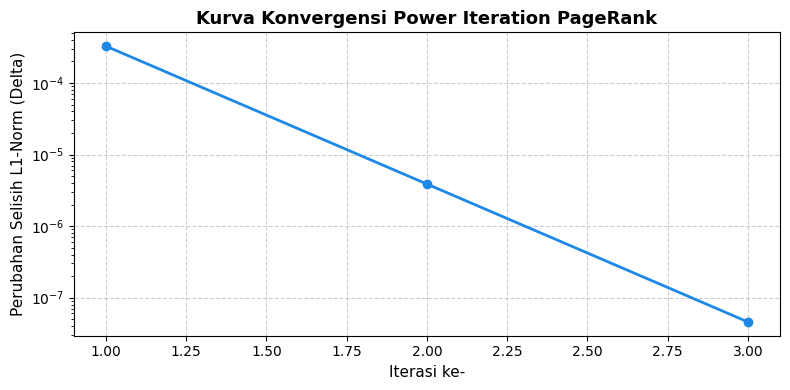

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(conv_hist) + 1), conv_hist, marker='o', color='#1E88E5', linewidth=2)
plt.title("Kurva Konvergensi Power Iteration PageRank", fontsize=13, fontweight='bold')
plt.xlabel("Iterasi ke-", fontsize=11)
plt.ylabel("Perubahan Selisih L1-Norm (Delta)", fontsize=11)
plt.yscale("log")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## 8. Visualisasi Graf Jaringan Web

Kita memvisualisasikan struktur graf jaringan web menggunakan `matplotlib`:
- Ukuran simpul (*node*) dibuat proporsional terhadap nilai PageRank.
- Warna simpul menunjukkan tingkatan nilai otoritas halaman.

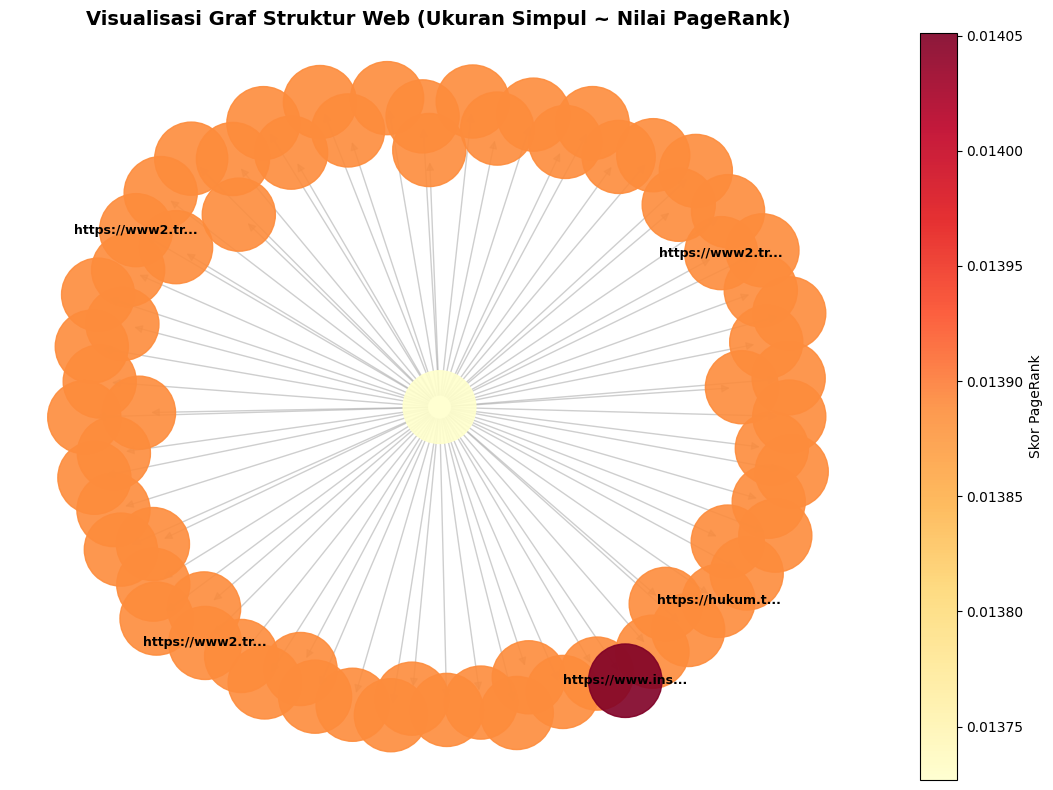

In [9]:
plt.figure(figsize=(11, 8))

# Ambil subgraf atau graf penuh
pos = nx.spring_layout(G, k=0.5, iterations=50, seed=42)

# Normalisasi ukuran node berdasarkan skor PageRank
pr_values = [custom_pr.get(node, 0.0) for node in G.nodes()]
node_sizes = [300 + (score / max(pr_values)) * 2500 for score in pr_values]

# Gambar edges dan nodes
nx.draw_networkx_edges(G, pos, edge_color="#9E9E9E", alpha=0.5, arrows=True, arrowsize=12, width=1.0)
nodes_plot = nx.draw_networkx_nodes(
    G, pos,
    node_size=node_sizes,
    node_color=pr_values,
    cmap=plt.cm.YlOrRd,
    alpha=0.9
)

# Label untuk 5 website dengan skor tertinggi
top_5_nodes = df_result.head(5)["url"].tolist()
labels = {node: nodes_dict[node]["title"][:15] + "..." for node in top_5_nodes if node in G}
nx.draw_networkx_labels(G, pos, labels=labels, font_size=9, font_weight="bold")

plt.colorbar(nodes_plot, label="Skor PageRank")
plt.title("Visualisasi Graf Struktur Web (Ukuran Simpul ~ Nilai PageRank)", fontsize=14, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

## 9. Analisis Hasil & Peringkat Website Terpenting

Berikut adalah tabel 10 website/halaman dengan pengaruh paling tinggi berdasarkan algoritma PageRank:

In [10]:
top_10 = df_result.head(10)[["rank", "title", "url", "pagerank_custom", "in_degree", "out_degree"]]
print("=== 10 WEBSITE TERPENTING BERDASARKAN PAGERANK ===")
top_10

=== 10 WEBSITE TERPENTING BERDASARKAN PAGERANK ===


,rank,title,url,pagerank_custom,in_degree,out_degree
0,1,https://www.instagram.com/universitastrunojoyo...,https://www.instagram.com/universitastrunojoyo...,0.014051,1,0
1,2,https://www2.trunojoyo.ac.id/sejarahutm,https://www2.trunojoyo.ac.id/sejarahutm,0.013889,1,0
2,3,https://www2.trunojoyo.ac.id/visimisi,https://www2.trunojoyo.ac.id/visimisi,0.013889,1,0
3,4,https://www2.trunojoyo.ac.id/index.php/profil-...,https://www2.trunojoyo.ac.id/index.php/profil-...,0.013889,1,0
4,5,https://hukum.trunojoyo.ac.id/,https://hukum.trunojoyo.ac.id/,0.013889,1,0
5,6,https://www2.trunojoyo.ac.id/organ-utm,https://www2.trunojoyo.ac.id/organ-utm,0.013889,1,0
6,7,https://feb.trunojoyo.ac.id/,https://feb.trunojoyo.ac.id/,0.013889,1,0
7,8,https://www2.trunojoyo.ac.id/lhm,https://www2.trunojoyo.ac.id/lhm,0.013889,1,0
8,9,https://www.facebook.com/people/Universitas-Tr...,https://www.facebook.com/people/Universitas-Tr...,0.013889,1,0
9,10,https://pertanian.trunojoyo.ac.id/,https://pertanian.trunojoyo.ac.id/,0.013889,1,0


### Interpretasi dan Pembahasan:
1. **Hubungan antara In-Degree dan PageRank:** Halaman dengan nilai PageRank tertinggi umumnya memiliki jumlah *in-degree* (backlinks) yang besar atau mendapatkan rujukan langsung dari halaman berbobot tinggi (seperti halaman beranda/homepage).
2. **Kualitas Tautan:** Tidak hanya jumlah kuantitas link yang penting, tetapi otoritas dari halaman pengarah juga berkontribusi besar. Satu tautan dari halaman utama berbobot tinggi dapat memberikan nilai PageRank yang lebih signifikan daripada banyak tautan dari halaman berbobot rendah.
3. **Peringkat #1:** Halaman dengan peringkat teratas merupakan pusat informasi (*authority hub*) yang menjadi simpul sentral navigasi pada struktur website tersebut.

## 10. Persiapan dan Deployment Aplikasi Interaktif (`app.py`)

Seluruh algoritma dan alur kerja di atas telah diintegrasikan ke dalam aplikasi web interaktif berbasis **Streamlit** pada berkas `app.py`.

### Cara Menjalankan Aplikasi di Lokal:
```bash
streamlit run app.py
```

### Cara Menjalankan Aplikasi di Server Warga Laboratorium:
```bash
# Masuk ke direktori proyek di server lab
cd /path/ke/proyek

# Install dependensi
pip install -r requirements.txt

# Jalankan Streamlit dengan binding port lab publik
streamlit run app.py --server.port 8501 --server.address 0.0.0.0
```
Dosen dan rekan mahasiswa kemudian dapat mengakses aplikasi secara langsung melalui peramban pada alamat:
`http://<IP-SERVER-LAB>:8501`